In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler,LabelEncoder
from sklearn.impute import SimpleImputer

In [ ]:
df = pd.read_csv('/content/pokemon.csv')
print("Dataset loaded successfully")
df.head()

Dataset loaded successfully


,index_name,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary,total_power
0,1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False,98
1,2,Ivysaur,Grass,Poison,60,62,63,80,80,60,1,False,125
2,3,Venusaur,Grass,Poison,80,82,83,100,100,80,1,False,165
3,4,Mega Venusaur,Grass,Poison,80,100,123,122,120,80,1,False,223
4,5,Charmander,Fire,NaN,39,52,43,60,50,65,1,False,95


In [ ]:
print(df.shape)
df.info()

(800, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   index_name   800 non-null    int64 
 1   Name         799 non-null    object
 2   Type 1       800 non-null    object
 3   Type 2       414 non-null    object
 4   HP           800 non-null    int64 
 5   Attack       800 non-null    int64 
 6   Defense      800 non-null    int64 
 7   Sp. Atk      800 non-null    int64 
 8   Sp. Def      800 non-null    int64 
 9   Speed        800 non-null    int64 
 10  Generation   800 non-null    int64 
 11  Legendary    800 non-null    bool  
 12  total_power  800 non-null    int64 
dtypes: bool(1), int64(9), object(3)
memory usage: 75.9+ KB


In [ ]:
df.describe()

,#,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,362.813750,435.10250,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375
std,208.343798,119.96304,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129
min,1.000000,180.00000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000
25%,184.750000,330.00000,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000
50%,364.500000,450.00000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000
75%,539.250000,515.00000,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000
max,721.000000,780.00000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000


In [ ]:
df.isnull().sum()

,0
#,0
Name,0
Type 1,0
Type 2,386
Total,0
HP,0
Attack,0
Defense,0
Sp. Atk,0
Sp. Def,0


In [ ]:
print("No of duplicste rows:",df.duplicated().sum())

No of duplicste rows: 0


In [ ]:
df['Type 2'].fillna(df['Type 2'].mode()[0],inplace=True)

/tmp/ipykernel_1778/641851713.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Type 2'].fillna(df['Type 2'].mode()[0],inplace=True)


In [ ]:
df.isnull().sum()

,0
#,0
Name,0
Type 1,0
Type 2,0
Total,0
HP,0
Attack,0
Defense,0
Sp. Atk,0
Sp. Def,0


In [ ]:
# Apply lable encoding
le = LabelEncoder()
df['Type 1'] = le.fit_transform(df['Type 1'])
df['Type 2'] = le.fit_transform(df['Type 2'])
print(df.head())

   #                   Name  Type 1  Type 2  Total  HP  Attack  Defense  \
0  1              Bulbasaur       9      13    318  45      49       49   
1  2                Ivysaur       9      13    405  60      62       63   
2  3               Venusaur       9      13    525  80      82       83   
3  3  VenusaurMega Venusaur       9      13    625  80     100      123   
4  4             Charmander       6       7    309  39      52       43   

   Sp. Atk  Sp. Def  Speed  Generation  Legendary  
0       65       65     45           1      False  
1       80       80     60           1      False  
2      100      100     80           1      False  
3      122      120     80           1      False  
4       60       50     65           1      False  


In [ ]:
# Apply onehot encoding
df = pd.get_dummies(df,columns=['Legendary'])
print(df.head())

   #                   Name  Type 1  Type 2  Total  HP  Attack  Defense  \
0  1              Bulbasaur       9      13    318  45      49       49   
1  2                Ivysaur       9      13    405  60      62       63   
2  3               Venusaur       9      13    525  80      82       83   
3  3  VenusaurMega Venusaur       9      13    625  80     100      123   
4  4             Charmander       6       7    309  39      52       43   

   Sp. Atk  Sp. Def  Speed  Generation  Legendary_False  Legendary_True  
0       65       65     45           1             True           False  
1       80       80     60           1             True           False  
2      100      100     80           1             True           False  
3      122      120     80           1             True           False  
4       60       50     65           1             True           False  


In [ ]:
# Apply normalization
scaler = MinMaxScaler()
df['Total'] = scaler.fit_transform(df[['Total']])
print(df.head())

   #                   Name  Type 1  Type 2     Total  HP  Attack  Defense  \
0  1              Bulbasaur       9      13  0.230000  45      49       49   
1  2                Ivysaur       9      13  0.375000  60      62       63   
2  3               Venusaur       9      13  0.575000  80      82       83   
3  3  VenusaurMega Venusaur       9      13  0.741667  80     100      123   
4  4             Charmander       6       7  0.215000  39      52       43   

   Sp. Atk  Sp. Def  Speed  Generation  Legendary_False  Legendary_True  
0       65       65     45           1             True           False  
1       80       80     60           1             True           False  
2      100      100     80           1             True           False  
3      122      120     80           1             True           False  
4       60       50     65           1             True           False  


In [ ]:
# create a new feature 'Defence and Attacking' as Defence+Attack
df['Defence and Attacking'] = df['Defense'] + df['Attack']
print(df.head())

   #                   Name  Type 1  Type 2     Total  HP  Attack  Defense  \
0  1              Bulbasaur       9      13  0.230000  45      49       49   
1  2                Ivysaur       9      13  0.375000  60      62       63   
2  3               Venusaur       9      13  0.575000  80      82       83   
3  3  VenusaurMega Venusaur       9      13  0.741667  80     100      123   
4  4             Charmander       6       7  0.215000  39      52       43   

   Sp. Atk  Sp. Def  Speed  Generation  Legendary_False  Legendary_True  \
0       65       65     45           1             True           False   
1       80       80     60           1             True           False   
2      100      100     80           1             True           False   
3      122      120     80           1             True           False   
4       60       50     65           1             True           False   

   Defence and Accacking  RareSpecies Attacking or Not  Defence and Attacking  


In [ ]:
# create a new feature 'Attacking or Not' from Attack where grater than 50 indicates attacking
df['Attacking or Not'] = df['Attack'].apply(lambda x: 'Attacking' if x > 70 else 'Not Attacking')
print(df.head())

   #                   Name  Type 1  Type 2     Total  HP  Attack  Defense  \
0  1              Bulbasaur       9      13  0.230000  45      49       49   
1  2                Ivysaur       9      13  0.375000  60      62       63   
2  3               Venusaur       9      13  0.575000  80      82       83   
3  3  VenusaurMega Venusaur       9      13  0.741667  80     100      123   
4  4             Charmander       6       7  0.215000  39      52       43   

   Sp. Atk  Sp. Def  Speed  Generation  Legendary_False  Legendary_True  \
0       65       65     45           1             True           False   
1       80       80     60           1             True           False   
2      100      100     80           1             True           False   
3      122      120     80           1             True           False   
4       60       50     65           1             True           False   

   Defence and Accacking  RareSpecies Attacking or Not  
0                     9

In [ ]:
# Add 'Defence and Attacking' and 'Attacking or Not' features to the dataset
df['Defence and Attacking'] = df['Defense'] + df['Attack']
df['Attacking or Not'] = df['Attack'].apply(lambda x: 'Attacking' if x > 70 else 'Not Attacking')
print("Defence and Attacking,Attacking or Not features added to the dataset")

Defence and Attacking,Attacking or Not features added to the dataset


In [ ]:
# outlier detection Defense
Q1 = df['Defense'].quantile(0.25)
Q3 = df['Defense'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['Defense'] >= lower_bound) & (df['Defense'] <= upper_bound)]
print("Outliers removed")

Outliers removed


In [ ]:
# outlier detection Defense
Q1 = df['Attack'].quantile(0.25)
Q3 = df['Attack'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['Attack'] >= lower_bound) & (df['Attack'] <= upper_bound)]
print("Outliers removed")

Outliers removed


In [ ]:
print("DataSet shape after removing outliers:",df.shape)

DataSet shape after removing outliers: (781, 18)


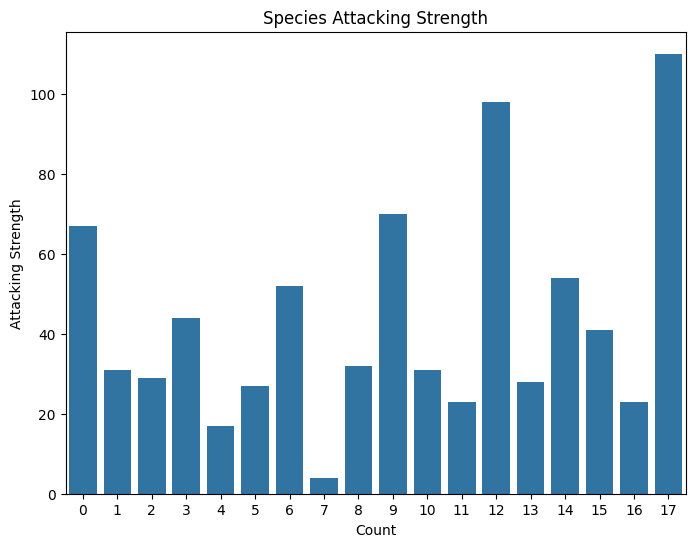

In [ ]:
#(Univariate Visualization) plot the count of passengers who Survived vs did not survived
plt.figure(figsize=(8,6))
sns.countplot(x='Type 1',data=df)
plt.title('Types Of Species')
plt.xlabel('Count')
plt.ylabel('Frequency')
plt.show()

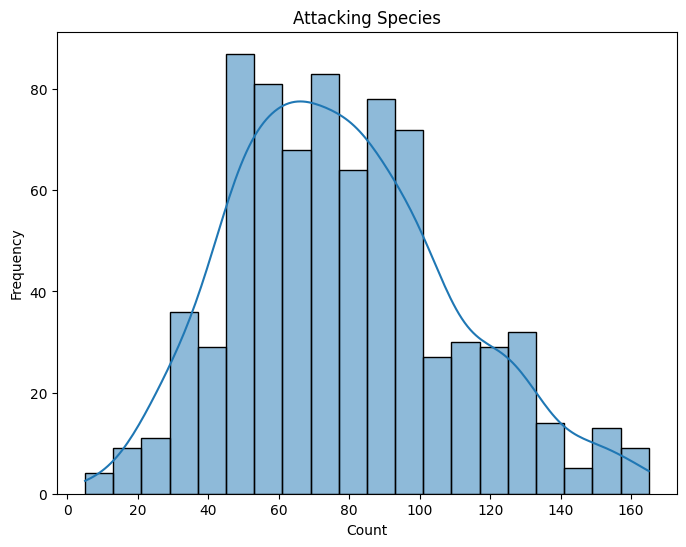

In [ ]:
# plot the distribution of passenger ages
plt.figure(figsize=(8,6))
sns.histplot(df['Attack'],bins=20,kde=True)
plt.title('Attacking Species')
plt.xlabel('Count')
plt.ylabel('Frequency')
plt.show()

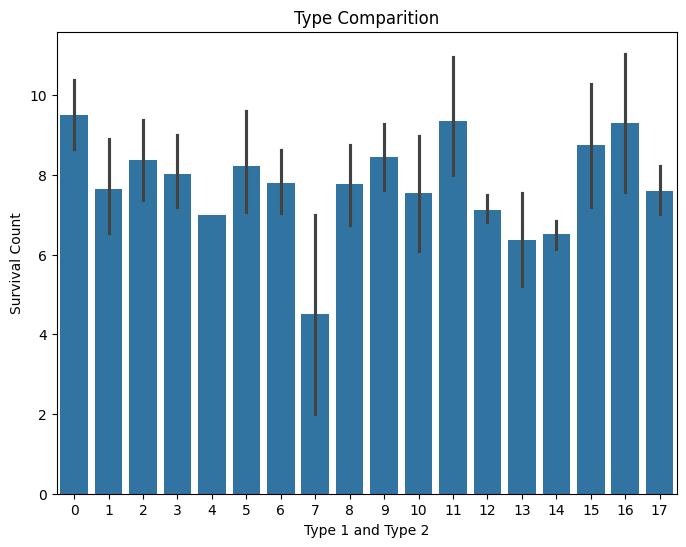

In [ ]:
# Bivariate Visualization bar chart as Survival counts b Sex
plt.figure(figsize=(8,6))
sns.barplot(x='Type 1',y='Type 2',data=df)
plt.title('Type Comparition')
plt.xlabel('Type 1 and Type 2')
plt.ylabel('Survival Count')
plt.show()

In [ ]:
# Drop columns Legendary_True and Ticket
df.drop(['Name','HP'],axis=1,inplace=True)
print('Columns dropped successfully')

Columns dropped successfully


In [ ]:
# Display side-by-side comparision of raw vs processed dataset(first 10 rows)
# Before vs After data comparision
print("After preprocessing")
display(df.head(10))

After preprocessing


,#,Type 1,Type 2,Total,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary_False,Legendary_True,Defence and Accacking,RareSpecies,Attacking or Not,Defence and Attacking
0,1,9,13,0.230000,49,49,65,65,45,1,True,False,98,RareSpecies,Not Attacking,98
1,2,9,13,0.375000,62,63,80,80,60,1,True,False,125,RareSpecies,Not Attacking,125
2,3,9,13,0.575000,82,83,100,100,80,1,True,False,165,RareSpecies,Attacking,165
3,3,9,13,0.741667,100,123,122,120,80,1,True,False,223,RareSpecies,Attacking,223
4,4,6,7,0.215000,52,43,60,50,65,1,True,False,95,RareSpecies,Not Attacking,95
5,5,6,7,0.375000,64,58,80,65,80,1,True,False,122,RareSpecies,Not Attacking,122
6,6,6,7,0.590000,84,78,109,85,100,1,True,False,162,RareSpecies,Attacking,162
7,6,6,2,0.756667,130,111,130,85,100,1,True,False,241,RareSpecies,Attacking,241
8,6,6,7,0.756667,104,78,159,115,100,1,True,False,182,RareSpecies,Attacking,182
9,7,17,7,0.223333,48,65,50,64,43,1,True,False,113,RareSpecies,Not Attacking,113
